In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pywt
!pip install optuna
import optuna
!pip install keras-tuner
import logging
from scipy.signal import butter, filtfilt
from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense, Dropout
import keras_tuner as kt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 1.4 MB/s eta 0:00:00


# Load Data and Exploratory Data Analysis

In [ ]:
df = pd.read_excel("/content/Data Capstone Fix BGt.xlsx", parse_dates=['Tanggal'], index_col='Tanggal')

In [ ]:
df.head()

,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
Tanggal,,,,,,,,,
2018-01-01,87.0,27.2,30.2,22.7,2.5,0,0.0,5.4,1008.0
2018-01-02,85.0,27.3,32.4,24.2,2.7,0,100.0,3.5,1008.5
2018-01-03,77.0,29.7,32.6,24.6,2.1,0,65.0,4.0,1009.3
2018-01-04,80.0,28.3,31.8,25.2,2.3,0,43.8,5.2,1009.1
2018-01-05,81.0,28.4,32.2,24.3,2.4,6,56.3,2.8,1009.8


In [ ]:
df.isnull().sum()

,0
Kelembapan Rata-Rata Udara Harian (%),0
Temperatur Rata-Rata Harian,0
Temperatur Maksimum Harian,0
Temperature Minimum Harian,0
Angin Rata-Rata Harian (Knot),0
Curah Hujan,0
Penyinaran Harian (%),0
Penguapan Harian (mm),0
Tekanan Udara Harian (mb),0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# penanganan khusus TTU
df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.1)

/tmp/ipykernel_4090/2679362525.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.1)


visualisasi time series plot

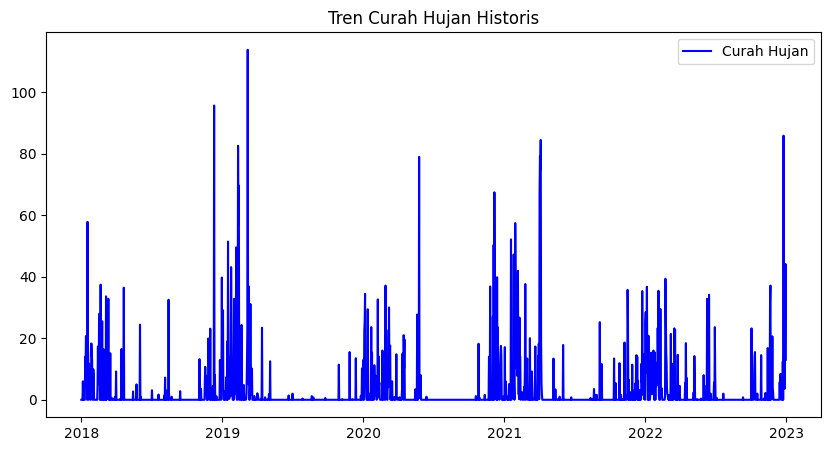

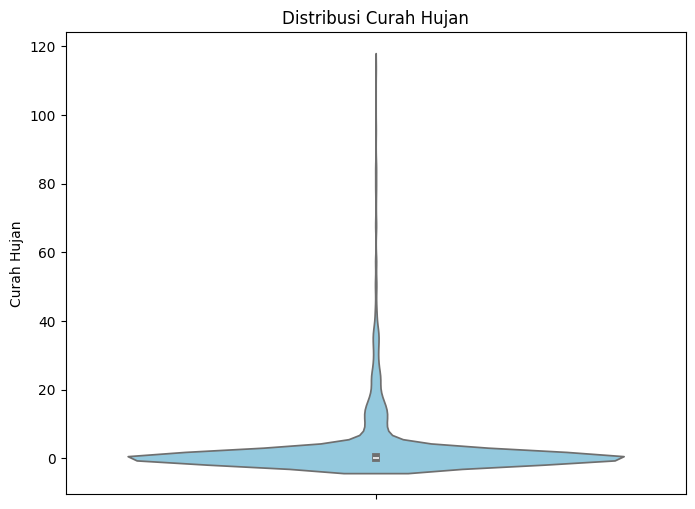

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df['Curah Hujan'], label='Curah Hujan', color='blue')
plt.title('Tren Curah Hujan Historis')
plt.legend()
plt.show()

plt.figure(figsize=(8,6))
sns.violinplot(y=df['Curah Hujan'], color='skyblue')
plt.title('Distribusi Curah Hujan')
plt.show()

violin plot ini menjelaskan kalau sebagian besar curah hujan berada di angka 0.

analisis autokorelasi

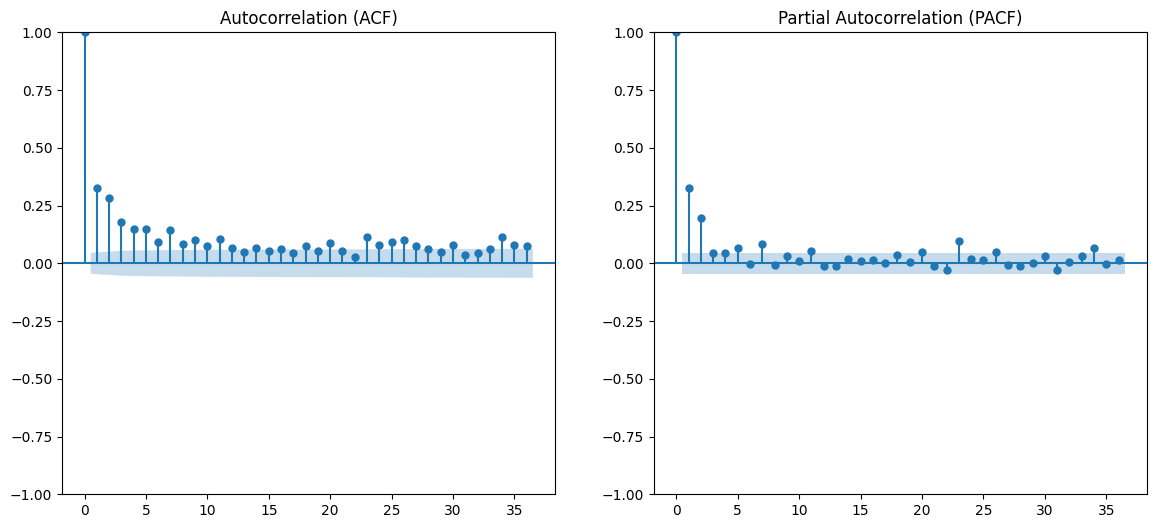

In [ ]:
plt.figure(figsize=(14, 6))
plt.subplot(121)
plot_acf(df['Curah Hujan'], lags=36, ax=plt.gca()) # Cek korelasi hingga 3 tahun (36 bulan) ke belakang
plt.title('Autocorrelation (ACF)')

plt.subplot(122)
plot_pacf(df['Curah Hujan'], lags=36, ax=plt.gca())
plt.title('Partial Autocorrelation (PACF)')
plt.show()

plot acf : Curah hujan hari ini masih dipengaruhi oleh beberapa hari sebelumnya, terutama 1–3 hari terakhir.

PACF : Pengaruh utama datang dari 1–2 periode sebelumnya saja

mungkin timestepnya cukup 3-7

Correlation MAtrix

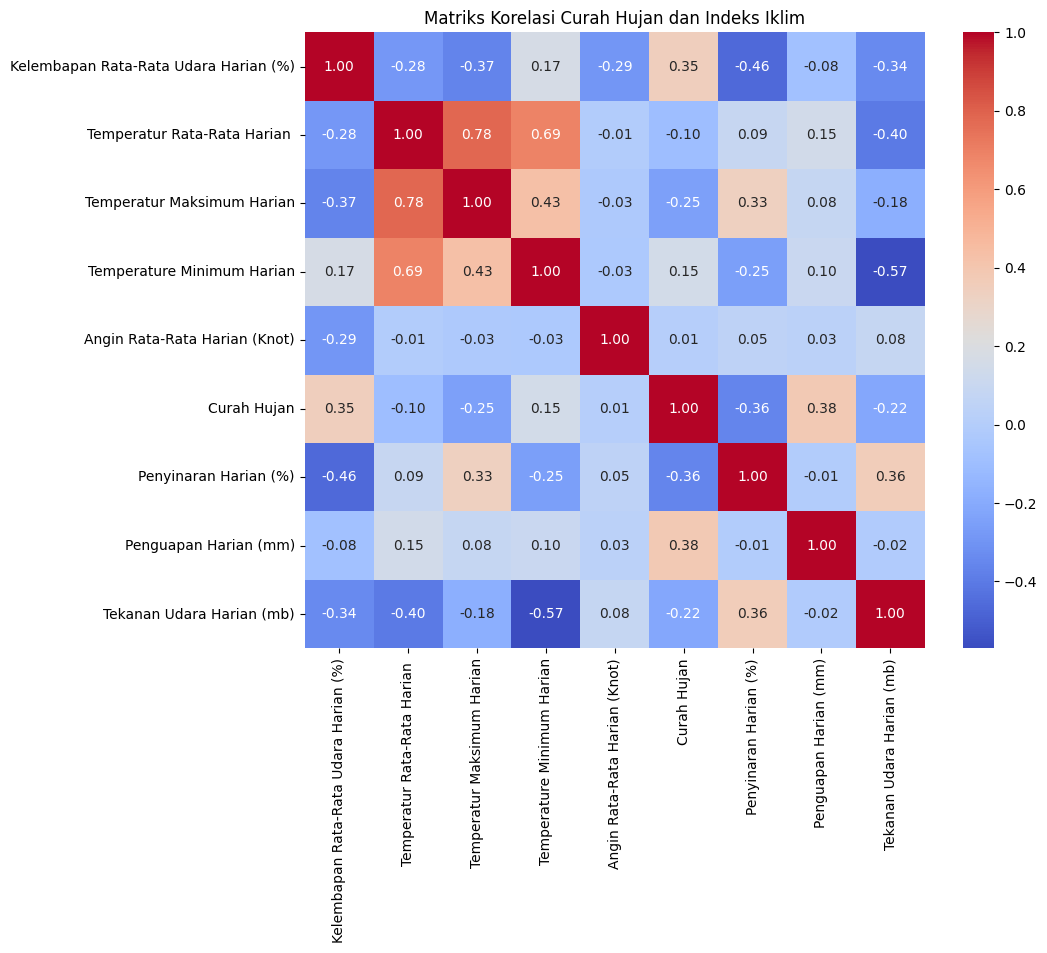

In [ ]:
# Cek korelasi linear biasa (Pearson)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Curah Hujan dan Indeks Iklim')
plt.show()

uji stasioneritas

karena svm biasanya butuh data yang stasioner

In [ ]:
result = adfuller(df['Curah Hujan'].dropna())
print('ADF Statistic:', result[0])
print('p-value:', result[1])

if result[1] <= 0.05:
    print("Data kuat dugaan Stasioner (Siap untuk SVM/LSTM).")
else:
    print("Data Non-Stasioner")

ADF Statistic: -5.989552308029646
p-value: 1.7589339485935783e-07
Data kuat dugaan Stasioner (Siap untuk SVM/LSTM).


# Preprocessing + Pseudo-Wavelet

In [ ]:
cols_to_use = [
    'Curah Hujan',                            # Target (Index 0)
    'Kelembapan Rata-Rata Udara Harian (%)',  # Fitur Pembantu 1
    'Penyinaran Harian (%)',                  # Fitur Pembantu 2
    'Penguapan Harian (mm)'                   # Fitur Pembantu 3
]

alasan tiga kolom itu dipakai :

- Kelembapan Rata-Rata Udara (%) -> 0.35

- Penguapan Harian -> 0.38

- Penyinaran  Harian-> -0.36 (tapi ini kalau penyinaran matahari tinggi berarti kemarau begitupun sebaliknya)

In [ ]:
df_selected = df[cols_to_use]

# Normalisasi data ke skala 0-1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df_selected)

# Target array (y)
y_scaled = scaled_data[:, 0]

# Fungsi Filter & Sliding Window

In [ ]:
def apply_pseudo_wavelet(data, cutoff=0.2, fs=1.0):
    """Pengganti PyWavelets untuk environment VM Ubuntu"""
    b, a = butter(N=4, Wn=cutoff, btype='low', fs=fs)
    approximation = filtfilt(b, a, data)
    detail = data - approximation
    return approximation, detail

def create_sliding_window(X_data, y_data, time_steps):
    X, y = [], []
    for i in range(len(X_data) - time_steps):
        X.append(X_data[i:(i + time_steps)])
        y.append(y_data[i + time_steps])
    return np.array(X), np.array(y)

def prepare_dataset(time_steps, use_wavelet):
    """Fungsi dinamis merakit dataset sesuai time_steps (hari) dari Optuna"""
    if use_wavelet:
        # Terapkan filter hanya pada kolom target (Curah Hujan) untuk menangkap ekstremnya
        A_rain, D_rain = apply_pseudo_wavelet(scaled_data[:, 0])
        # Susun ulang: [Approximation, Detail, Kelembapan, Penyinaran, Penguapan]
        data_to_window = np.column_stack((A_rain, D_rain, scaled_data[:, 1:]))
    else:
        data_to_window = scaled_data

    X, y = create_sliding_window(data_to_window, y_scaled, time_steps)

    # Split 80% Train, 20% Test
    split_idx = int(len(X) * 0.8)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    return X_train, X_test, y_train, y_test

# Objective Function Optuna

In [ ]:
def objective(trial, model_type, use_wavelet):
    # Tuning Jendela Waktu (Karena data harian, kita coba lihat 3 sampai 7 HARI ke belakang)
    time_steps = trial.suggest_int('time_steps', 3, 7)

    X_train, X_test, y_train, y_test = prepare_dataset(time_steps, use_wavelet)

    if model_type == 'svm':
        c_val = trial.suggest_float('C', 1e-1, 1e2, log=True)
        gamma_val = trial.suggest_categorical('gamma', ['scale', 'auto'])

        # Reshape 3D -> 2D
        X_tr_2d = X_train.reshape((X_train.shape[0], -1))
        X_ts_2d = X_test.reshape((X_test.shape[0], -1))

        model = SVR(kernel='rbf', C=c_val, gamma=gamma_val)
        model.fit(X_tr_2d, y_train)
        preds = model.predict(X_ts_2d)

    elif model_type == 'lstm':
        units = trial.suggest_int('lstm_units', 32, 128, step=32)
        lr = trial.suggest_categorical('learning_rate', [1e-2, 1e-3, 1e-4])

        model = Sequential([
            LSTM(units, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
            Dense(1)
        ])
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
        model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)
        preds = model.predict(X_test, verbose=0).flatten()

    elif model_type == 'lstm_svm':
        units = trial.suggest_int('lstm_units', 32, 128, step=32)
        c_val = trial.suggest_float('svm_C', 1e-1, 1e2, log=True)

        # Ekstraktor Fitur LSTM
        lstm_net = Sequential([
            LSTM(units, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
            Dense(1)
        ])
        lstm_net.compile(optimizer='adam', loss='mse')
        lstm_net.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)

        feature_extractor = Model(inputs=lstm_net.inputs, outputs=lstm_net.layers[0].output)
        X_tr_feat = feature_extractor.predict(X_train, verbose=0)
        X_ts_feat = feature_extractor.predict(X_test, verbose=0)

        # Prediktor Final SVM
        svm = SVR(kernel='rbf', C=c_val, gamma='scale')
        svm.fit(X_tr_feat, y_train)
        preds = svm.predict(X_ts_feat)

    # Kembalikan nilai RMSE
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    return rmse

# Modeling

In [ ]:
studies_config = {
    "1. Base SVM":       {'type': 'svm',      'wavelet': False},
    "2. W-SVM":          {'type': 'svm',      'wavelet': True},
    "3. Base LSTM":      {'type': 'lstm',     'wavelet': False},
    "4. W-LSTM":         {'type': 'lstm',     'wavelet': True},
    "5. Base LSTM-SVM":  {'type': 'lstm_svm', 'wavelet': False},
    "6. W-LSTM-SVM":     {'type': 'lstm_svm', 'wavelet': True}
}

In [ ]:
best_results = {}
for name, config in studies_config.items():
    print(f"-> Tuning {name}...")
    study = optuna.create_study(direction='minimize')
    # Gunakan n_trials=10 untuk kecepatan, naikkan ke 30-50 nanti jika butuh hasil final
    study.optimize(lambda trial: objective(trial, config['type'], config['wavelet']), n_trials=30)

    best_results[name] = {
        'RMSE': study.best_value,
        'Params': study.best_params
    }
    print(f"Selesai! RMSE: {study.best_value:.4f}\n")

[I 2026-05-08 06:45:55,449] A new study created in memory with name: no-name-48ae3e09-f3e4-46ba-af80-0729a9342979


-> Tuning 1. Base SVM...


[I 2026-05-08 06:45:55,924] Trial 0 finished with value: 0.10521366128688842 and parameters: {'time_steps': 7, 'C': 95.55011058550798, 'gamma': 'scale'}. Best is trial 0 with value: 0.10521366128688842.
[I 2026-05-08 06:45:56,621] Trial 1 finished with value: 0.10496272568917932 and parameters: {'time_steps': 3, 'C': 46.39199196574848, 'gamma': 'scale'}. Best is trial 1 with value: 0.10496272568917932.
[I 2026-05-08 06:45:56,805] Trial 2 finished with value: 0.09734180609505141 and parameters: {'time_steps': 5, 'C': 2.952941346490121, 'gamma': 'auto'}. Best is trial 2 with value: 0.09734180609505141.
[I 2026-05-08 06:45:56,918] Trial 3 finished with value: 0.09965363917479865 and parameters: {'time_steps': 3, 'C': 0.4069114354715736, 'gamma': 'auto'}. Best is trial 2 with value: 0.09734180609505141.
[I 2026-05-08 06:45:56,994] Trial 4 finished with value: 0.09881708534132118 and parameters: {'time_steps': 3, 'C': 2.9206853606188776, 'gamma': 'auto'}. Best is trial 2 with value: 0.09734

Selesai! RMSE: 0.0934

-> Tuning 2. W-SVM...


[I 2026-05-08 06:46:01,962] Trial 3 finished with value: 0.050973485525075114 and parameters: {'time_steps': 4, 'C': 3.7181280059535413, 'gamma': 'scale'}. Best is trial 3 with value: 0.050973485525075114.
[I 2026-05-08 06:46:02,021] Trial 4 finished with value: 0.05138725398732627 and parameters: {'time_steps': 4, 'C': 85.10932272437721, 'gamma': 'auto'}. Best is trial 3 with value: 0.050973485525075114.
[I 2026-05-08 06:46:02,089] Trial 5 finished with value: 0.08878092674941654 and parameters: {'time_steps': 4, 'C': 0.5344298378334892, 'gamma': 'auto'}. Best is trial 3 with value: 0.050973485525075114.
[I 2026-05-08 06:46:02,155] Trial 6 finished with value: 0.07473313329943052 and parameters: {'time_steps': 4, 'C': 1.7403146167326518, 'gamma': 'auto'}. Best is trial 3 with value: 0.050973485525075114.
[I 2026-05-08 06:46:02,233] Trial 7 finished with value: 0.07682916934990608 and parameters: {'time_steps': 5, 'C': 1.7586509531498844, 'gamma': 'auto'}. Best is trial 3 with value: 0

...

Selesai! RMSE: 0.0235

-> Tuning 5. Base LSTM-SVM...


[I 2026-05-08 06:54:45,966] Trial 0 finished with value: 0.10337970772090047 and parameters: {'time_steps': 3, 'lstm_units': 32, 'svm_C': 25.32031671579576}. Best is trial 0 with value: 0.10337970772090047.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2026-05-08 06:54:59,066] Trial 1 finished with value: 0.10406536751246061 and parameters: {'time_steps': 7, 'lstm_units': 128, 'svm_C': 2.9145695753728207}. Best is trial 0 with value: 0.10337970772090047.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2026-05-0

Selesai! RMSE: 0.0916

-> Tuning 6. W-LSTM-SVM...


[I 2026-05-08 06:58:48,991] Trial 0 finished with value: 0.0483910351224903 and parameters: {'time_steps': 7, 'lstm_units': 32, 'svm_C': 39.309242844367034}. Best is trial 0 with value: 0.0483910351224903.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2026-05-08 06:58:56,907] Trial 1 finished with value: 0.0590004610467616 and parameters: {'time_steps': 6, 'lstm_units': 64, 'svm_C': 0.16156526480223157}. Best is trial 0 with value: 0.0483910351224903.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2026-05-08 0

Selesai! RMSE: 0.0399



In [ ]:
print("\n" + "="*40 + "\nREKAP HASIL UNIVARIATE\n" + "="*40)
for m, res in best_results.items():
    print(f"{m}: RMSE {res['RMSE']:.4f} | Params: {res}")


REKAP HASIL UNIVARIATE
1. Base SVM: RMSE 0.0934 | Params: {'RMSE': 0.09342428667001919, 'Params': {'time_steps': 4, 'C': 11.976118783126786, 'gamma': 'scale'}}
2. W-SVM: RMSE 0.0496 | Params: {'RMSE': 0.04957268570790491, 'Params': {'time_steps': 3, 'C': 2.499194585168857, 'gamma': 'scale'}}
3. Base LSTM: RMSE 0.0659 | Params: {'RMSE': 0.06592608656776436, 'Params': {'time_steps': 3, 'lstm_units': 96, 'learning_rate': 0.001}}
4. W-LSTM: RMSE 0.0235 | Params: {'RMSE': 0.023455968419936277, 'Params': {'time_steps': 6, 'lstm_units': 64, 'learning_rate': 0.01}}
5. Base LSTM-SVM: RMSE 0.0916 | Params: {'RMSE': 0.09155774549253973, 'Params': {'time_steps': 5, 'lstm_units': 64, 'svm_C': 98.465569336076}}
6. W-LSTM-SVM: RMSE 0.0399 | Params: {'RMSE': 0.03989871701708034, 'Params': {'time_steps': 6, 'lstm_units': 32, 'svm_C': 7.5241155963415025}}
